# Validación de la opción 3 (rectificada) contra LT medida — muestreo

Corre exactamente la **opción 3** (`fish_length_opcion3_rectificada.ipynb`: máscara YOLO-seg → rectificación al plano del ArUco → camino geodésico + eje con extensión recta, `LT_axial_cm`) sobre las imágenes de `Imagenes peces muestreo/` (2 imágenes por individuo, lados `a` y `b`) y compara con `total_length_cm` (LT) de `metadata.csv`.

Salidas: `outputs/muestreo_por_lado.xlsx` (ID_LADO) y `outputs/muestreo_por_individuo.xlsx` (ID, promedio de ambos lados). Si una imagen tiene varios peces detectados se usa el de mayor área de máscara.

In [1]:
%pip install -q numpy scipy opencv-contrib-python scikit-image matplotlib pandas ultralytics openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt
from scipy.signal import savgol_filter
from scipy.interpolate import splprep, splev
from skimage.graph import MCP_Geometric, route_through_array

import fish_length_utils as U

# ---------------- parámetros ----------------
# ---- modelo de segmentación a usar (cambiar acá)
WEIGHTS = r"C:\Users\juanm\Documents\GitHub\fish_cv_pfc\runs\yolo11s-seg_pescado_autofish-20261112T182943Z-1-001\yolo11s-seg_pescado_autofish\weights\best.pt"          # p. ej. U.RAIZ / "runs" / "yolov8n-seg_merged" / "weights" / "best.pt"
# ---- datos del muestreo
N_IMAGENES = None            # None = todas; o un entero (primeras N imágenes)
DIR_MUESTREO = U.RAIZ / "Imagenes peces muestreo"
CARPETA_IMAGENES = DIR_MUESTREO / "images"
CSV_METADATA = DIR_MUESTREO / "metadata.csv"
CONF, IMGSZ = U.CONF, U.IMGSZ
ARUCO_ID, TAMANO_ARUCO_CM = U.ARUCO_ID, U.TAMANO_ARUCO_CM
P_COSTO = 2                  # exponente p del costo 1/(dt+1)**p (probar 1, 2 y 3)
P_COMPARAR = (1, 2, 3)       # valores de p que se comparan en el CSV (el principal es P_COSTO)
SUAVIZADO = "savgol"         # "savgol" o "spline"
SUAV_FRAC = 0.15             # savgol: ventana = SUAV_FRAC * n_puntos del camino (impar, >= 11)
SPLINE_S_PX = 2.0            # spline: s = SPLINE_S_PX**2 * n_puntos (desvío cuadrático medio permitido, px)
LADO_MAX_PX = 1200           # reescala la máscara recortada si su lado mayor lo supera; None = sin reescalar
# ---- opción 2b (eje + extensión recta): fracciones de la longitud del camino
F_INI, F_REF, F_FIN = 0.55, 0.70, 0.80   # dirección del eje = punto(F_FIN) - punto(F_INI); origen O = punto(F_REF)
F_REF_DOBLADA = 0.60                     # F_REF alternativo si la cola está doblada
ANGULO_COLA_MAX = 30                     # grados entre el eje y el tramo 80 %-100 % para marcar cola_doblada
# ---- opción 3: rectificación al plano métrico
RES_PX_POR_CM = 20           # resolución de la máscara rectificada (px/cm); se reduce sola si supera LADO_MAX_PX
MARGEN_CM = 1.0              # margen alrededor del pez en la imagen rectificada
EXTENSION_MAX_CM = 300       # si el pez proyectado mide más que esto la homografía es degenerada: se omite el pez
SALIDA_IMGS = Path("outputs/muestreo_opcion3")
SALIDA_CSV = Path("outputs/muestreo_resultados_opcion3.csv")
SALIDA_XLSX_LADO = Path("outputs/muestreo_por_lado.xlsx")
SALIDA_XLSX_ID = Path("outputs/muestreo_por_individuo.xlsx")

## Funciones (copiadas de la opción 3)

In [3]:
def preparar_mascara(mask, px_por_cm, lado_max=LADO_MAX_PX):
    """Limpia la máscara, la recorta a su bounding box (con margen de 2 px) y, si el lado mayor supera `lado_max`,
    la reescala. Devuelve (m_bool, px_por_cm_esc, escala, (x0, y0)). Las coordenadas del recorte reescalado se llevan
    a la imagen original con: p_orig = p / escala + (x0, y0).  px_por_cm_esc = px_por_cm * escala."""
    m = U.limpiar_mascara(mask)
    ys, xs = np.nonzero(m)
    x0, y0 = max(xs.min() - 2, 0), max(ys.min() - 2, 0)
    m = m[y0:ys.max() + 3, x0:xs.max() + 3]
    escala = 1.0
    if lado_max and max(m.shape) > lado_max:
        escala = lado_max / max(m.shape)
        m = cv2.resize(m, None, fx=escala, fy=escala, interpolation=cv2.INTER_NEAREST)
    return m > 0, px_por_cm * escala, escala, (x0, y0)


def mas_lejano_geodesico(mask_bool, origen):
    """Punto (fila, col) de la máscara geodésicamente más lejano de `origen` (costo 1 dentro, inf fuera)."""
    costo = np.where(mask_bool, 1.0, np.inf)
    acum, _ = MCP_Geometric(costo, fully_connected=True).find_costs([tuple(origen)])
    acum = np.where(np.isfinite(acum), acum, -1)
    return np.unravel_index(np.argmax(acum), acum.shape)


def extremos_geodesicos(mask_bool):
    """Extremos A y B por diámetro geodésico (doble barrido). Devuelve (A, B) como (fila, col)."""
    ys, xs = np.nonzero(mask_bool)
    k = len(ys) // 2                      # un píxel cualquiera de la máscara
    A = mas_lejano_geodesico(mask_bool, (ys[k], xs[k]))
    B = mas_lejano_geodesico(mask_bool, A)
    return tuple(int(v) for v in A), tuple(int(v) for v in B)


def camino_centrado(mask_bool, A, B, p=P_COSTO):
    """Camino mínimo A→B con costo 1/(dt+1)**p dentro de la máscara (inf fuera). Devuelve array (N, 2) en (x, y)."""
    dt = distance_transform_edt(mask_bool)
    costo = np.where(mask_bool, 1.0 / (dt + 1.0) ** p, np.inf)
    ruta, _ = route_through_array(costo, A, B, fully_connected=True, geometric=True)
    ruta = np.asarray(ruta, dtype=np.float64)
    return ruta[:, ::-1]                  # (fila, col) -> (x, y)


def suavizar_camino(xy, metodo=SUAVIZADO, frac=SUAV_FRAC, s_px=SPLINE_S_PX):
    """Suaviza el camino (N, 2) manteniendo los extremos fijos. 'savgol' (ventana relativa, polinomio de grado 3)
    o 'spline' (spline cúbica suavizada)."""
    n = len(xy)
    if n < 15:
        return xy
    if metodo == "savgol":
        w = max(11, int(frac * n) | 1)
        w = min(w, n if n % 2 else n - 1)
        sm = np.column_stack([savgol_filter(xy[:, 0], w, 3, mode="interp"), savgol_filter(xy[:, 1], w, 3, mode="interp")])
    else:
        tck, _ = splprep(xy.T, s=(s_px ** 2) * n, k=3)
        sm = np.column_stack(splev(np.linspace(0, 1, n * 2), tck))
    sm[0], sm[-1] = xy[0], xy[-1]         # los extremos geodésicos se respetan
    return sm


def longitud(xy):
    """Longitud de la poligonal (N, 2)."""
    return float(np.sum(np.linalg.norm(np.diff(xy, axis=0), axis=1)))


def _axial(mb, path, cum, dt_unused, f_ini, f_ref, f_fin):
    """Cálculo de la opción 2b para un camino ya orientado cabeza→cola (filas/cols) y su longitud acumulada `cum`.
    Devuelve dict con L_px, path_final, punta_lobulo, d, O, t_max, angulo_cola (grados) o None si el eje es degenerado."""
    idx = lambda f: min(int(np.searchsorted(cum, f * cum[-1])), len(path) - 1)
    i0, i1, i2 = idx(f_ini), idx(f_ref), idx(f_fin)
    d = path[i2] - path[i0]
    nd = np.linalg.norm(d)
    if nd < 1e-9:
        return None
    d = d / nd
    O = path[i1]
    coords = np.argwhere(mb)
    t = (coords - O) @ d
    t_max = float(t.max())
    punta_lobulo = coords[int(t.argmax())]
    punta_eje = O + t_max * d
    cola = path[-1] - path[i2]                      # tramo 80 %-100 % del camino (donde aparece el gancho)
    ncola = np.linalg.norm(cola)
    ang = float(np.degrees(np.arccos(np.clip(d @ cola / ncola, -1, 1)))) if ncola > 1e-9 else 0.0
    return dict(L_px=float(cum[i1] + t_max), path_final=np.vstack([path[:i1 + 1], punta_eje]),
                punta_lobulo=punta_lobulo, t_max=t_max, angulo_cola=ang, f_ref=f_ref)


def lt_axial(mb, path_xy, px_por_cm, f_ini=F_INI, f_ref=F_REF, f_fin=F_FIN):
    """Opción 2b: LT = arco del eje en el cuerpo + tramo recto hasta la punta del lóbulo más largo.

    `mb`: máscara booleana (recorte, escala de trabajo); `path_xy`: camino suavizado (N, 2) en (x, y).
    1) Orienta cabeza→cola (la cola es el extremo con menor DT media en el 20 % inicial/final).
    2) Eje = dirección entre los puntos al `f_ini` y `f_fin` de la longitud; origen O al `f_ref`.
    3) Proyecta todos los píxeles de la máscara sobre el eje: el de mayor t es la punta del lóbulo más largo.
    Si el ángulo entre el eje y el tramo 80 %-100 % supera ANGULO_COLA_MAX se marca `cola_doblada` y se repite con
    F_REF_DOBLADA. Devuelve dict con LT_axial_cm, path_final / hocico / punta_lobulo / punta_eje en (x, y) de la
    máscara de trabajo, cola_doblada, angulo_cola, f_ref_usado, tramo_recto_px. Con datos insuficientes: LT_axial_cm=NaN."""
    nan = dict(LT_axial_cm=np.nan, path_final=None, hocico=None, punta_lobulo=None, cola_doblada=False,
               angulo_cola=np.nan, f_ref_usado=np.nan, tramo_recto_px=np.nan)
    if len(path_xy) < 15 or mb.sum() < 50:
        return nan
    path = np.asarray(path_xy, float)[:, ::-1]                      # (x, y) -> (fila, col)
    dt = distance_transform_edt(mb)
    dt_medio = lambda s: dt[s.round().astype(int)[:, 0], s.round().astype(int)[:, 1]].mean()
    k = max(3, int(0.2 * len(path)))
    if dt_medio(path[:k]) < dt_medio(path[-k:]):                    # la cabeza debe ser el extremo "grueso"
        path = path[::-1]
    cum = np.r_[0, np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
    if cum[-1] < 1e-9:
        return nan
    r = _axial(mb, path, cum, dt, f_ini, f_ref, f_fin)
    if r is None:
        return nan
    doblada = r["angulo_cola"] > ANGULO_COLA_MAX
    if doblada:
        r2 = _axial(mb, path, cum, dt, f_ini, F_REF_DOBLADA, f_fin)
        r = r2 or r
    pf = r["path_final"]
    xy = lambda q: np.asarray(q, float)[::-1]
    return dict(LT_axial_cm=r["L_px"] / px_por_cm, path_final=pf[:, ::-1], hocico=xy(path[0]),
                punta_lobulo=xy(r["punta_lobulo"]), cola_doblada=bool(doblada), angulo_cola=r["angulo_cola"],
                f_ref_usado=r["f_ref"], tramo_recto_px=float(r["t_max"]))


def medir_geodesica(mask, px_por_cm, p=P_COSTO, metodo=SUAVIZADO, axial=True, H=None):
    """LT por camino geodésico centrado. Devuelve dict con LT_curva_cm, LT_recta_cm (y LT_axial_cm), camino (px de la
    imagen original), extremos A y B (x, y), contorno, escala usada y tiempo de cómputo (s).

    Los extremos y el camino se buscan en píxeles. Si se pasa la homografía `H` (px -> cm), las longitudes se calculan
    proyectando los puntos a cm (corrige perspectiva); si H es None se usa el factor `px_por_cm`. Las versiones con
    factor único siempre se devuelven en las claves *_escalar_cm."""
    t = U.cronometro()
    mb, ppc, escala, (x0, y0) = preparar_mascara(mask, px_por_cm)
    A, B = extremos_geodesicos(mb)
    ruta = camino_centrado(mb, A, B, p)
    liso = suavizar_camino(ruta, metodo)
    a_xy, b_xy = np.array(A[::-1], float), np.array(B[::-1], float)
    a_orig = lambda q: np.asarray(q) / escala + (x0, y0)
    camino, a, b = a_orig(liso), a_orig(a_xy), a_orig(b_xy)
    L = (lambda pts: U.longitud_cm(pts, H)) if H is not None else (lambda pts: longitud(pts) / px_por_cm)
    r = dict(LT_curva_cm=L(camino), LT_recta_cm=L(np.vstack([a, b])), LT_curva_sin_suavizar_cm=L(a_orig(ruta)),
             LT_curva_escalar_cm=longitud(liso) / ppc, LT_recta_escalar_cm=float(np.linalg.norm(a_xy - b_xy)) / ppc,
             camino=camino, a=a, b=b, contour=U.mayor_contorno(U.limpiar_mascara(mask)), escala=escala)
    ax = lt_axial(mb, liso, ppc) if axial else None
    if ax is not None:
        r.update(LT_axial_escalar_cm=ax["LT_axial_cm"], LT_axial_cm=ax["LT_axial_cm"], cola_doblada=ax["cola_doblada"],
                 angulo_cola=ax["angulo_cola"], f_ref_usado=ax["f_ref_usado"], tramo_recto_cm=ax["tramo_recto_px"] / ppc)
        if ax["path_final"] is not None:
            r.update(camino_axial=a_orig(ax["path_final"]), hocico=a_orig(ax["hocico"]), punta_lobulo=a_orig(ax["punta_lobulo"]))
            r["LT_axial_cm"] = L(r["camino_axial"])
            r["tramo_recto_cm"] = L(r["camino_axial"][-2:])      # último tramo (recto) en cm
    r["tiempo_s"] = t()
    return r

In [4]:
def rectificar_mascara(mask, H, res=RES_PX_POR_CM, margen_cm=MARGEN_CM, lado_max=LADO_MAX_PX, ext_max_cm=EXTENSION_MAX_CM):
    """Lleva la máscara del pez al plano métrico del ArUco con `cv2.warpPerspective`.

    Devuelve (m_bool, res_usada, Hr) o None si la homografía es degenerada. En la máscara rectificada 1 px = 1/res_usada cm
    (escala uniforme), de modo que distancias y caminos geodésicos se miden directamente en cm. `Hr` lleva píxeles de la
    imagen original a píxeles de la máscara rectificada (su inversa devuelve puntos a la imagen original)."""
    m = U.limpiar_mascara(mask)
    hull = cv2.convexHull(U.mayor_contorno(m)).reshape(-1, 2)
    cm = U.proyectar_cm(hull, H)
    if not np.all(np.isfinite(cm)):
        return None
    lo, hi = cm.min(0) - margen_cm, cm.max(0) + margen_cm
    ext = hi - lo
    if ext.max() > ext_max_cm or ext.min() <= 0:
        return None
    res = min(res, lado_max / ext.max())                        # tope de tamaño de la imagen rectificada
    T = np.array([[res, 0, -lo[0] * res], [0, res, -lo[1] * res], [0, 0, 1.0]])
    Hr = T @ np.asarray(H, dtype=np.float64)
    w, h = int(np.ceil(ext[0] * res)), int(np.ceil(ext[1] * res))
    w_img = cv2.warpPerspective(m, Hr, (w, h), flags=cv2.INTER_LINEAR)
    w_img = U.limpiar_mascara(((w_img > 127) * 255).astype(np.uint8), kernel_cierre=3)
    n, lab, stats, _ = cv2.connectedComponentsWithStats((w_img > 0).astype(np.uint8), connectivity=8)
    if n <= 1:
        return None
    mayor = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    return lab == mayor, res, Hr


def medir_rectificada(mask, H, p=P_COSTO, metodo=SUAVIZADO):
    """Opción 3: misma medición que la opción 2 (camino geodésico centrado + eje con extensión recta) pero sobre la
    máscara rectificada al plano métrico. Como la escala es uniforme, `LT_*_cm` = longitud en px / res. Devuelve dict con
    LT_curva_cm, LT_recta_cm, LT_axial_cm, cola_doblada, ..., y camino_axial / hocico / punta_lobulo / camino en píxeles
    de la imagen ORIGINAL (para dibujar). None si la rectificación falla."""
    t = U.cronometro()
    rr = rectificar_mascara(mask, H)
    if rr is None:
        return None
    mb, res, Hr = rr
    A, B = extremos_geodesicos(mb)
    ruta = camino_centrado(mb, A, B, p)
    liso = suavizar_camino(ruta, metodo)
    a_xy, b_xy = np.array(A[::-1], float), np.array(B[::-1], float)
    a_orig = lambda q: U.proyectar_cm(q, np.linalg.inv(Hr)) if len(np.atleast_2d(q)) else q   # rectificado -> imagen
    r = dict(LT_curva_cm=longitud(liso) / res, LT_recta_cm=float(np.linalg.norm(a_xy - b_xy)) / res,
             LT_curva_sin_suavizar_cm=longitud(ruta) / res, res_px_por_cm=res, camino=a_orig(liso),
             a=a_orig(a_xy[None])[0], b=a_orig(b_xy[None])[0], contour=U.mayor_contorno(U.limpiar_mascara(mask)))
    ax = lt_axial(mb, liso, res, F_INI, F_REF, F_FIN)
    r.update(LT_axial_cm=ax["LT_axial_cm"], cola_doblada=ax["cola_doblada"], angulo_cola=ax["angulo_cola"],
             f_ref_usado=ax["f_ref_usado"], tramo_recto_cm=ax["tramo_recto_px"] / res)
    if ax["path_final"] is not None:
        r.update(camino_axial=a_orig(ax["path_final"]), hocico=a_orig(ax["hocico"][None])[0],
                 punta_lobulo=a_orig(ax["punta_lobulo"][None])[0])
    r["tiempo_s"] = t()
    return r

## Medición de cada imagen del muestreo

In [5]:
model = U.cargar_modelo(WEIGHTS)
print("Modelo:", WEIGHTS)
meta = pd.read_csv(CSV_METADATA)
meta["imagen"] = meta["file_name"].map(lambda s: Path(s).name)
meta["ID_LADO"] = meta["imagen"].map(lambda s: Path(s).stem.replace("fish_", ""))      # p. ej. 13861_a
meta["ID"] = meta["specimen_id"].astype(int)
meta["lado"] = meta["ID_LADO"].str[-1]
LT_COL = "total_length_cm"

imgs = {p.name: p for p in U.listar_imagenes(CARPETA_IMAGENES, N_IMAGENES)}
filas, anotadas = [], {}
for nombre, path in imgs.items():
    prep = U.preparar_imagen(path, model, CONF, IMGSZ, ARUCO_ID, TAMANO_ARUCO_CM)
    fila = dict(imagen=nombre, estado=prep["estado"], LT_pred_cm=np.nan, n_peces=len(prep["masks"]))
    if prep["estado"] == "ok":
        k = int(np.argmax([(m > 0).sum() for m in prep["masks"]]))         # pez de mayor área
        r = medir_rectificada(prep["masks"][k], prep["H"])
        if r is None:
            fila["estado"] = "rectificacion_fallida"
        else:
            fila.update(LT_pred_cm=r["LT_axial_cm"], LT_curva_cm=r["LT_curva_cm"], LT_recta_cm=r["LT_recta_cm"],
                        cola_doblada=r["cola_doblada"], score=prep["confs"][k])
            if "camino_axial" in r:
                pez = dict(contour=r["contour"],
                           capas=[dict(tipo="linea", pts=r["camino_axial"], color=U.COLOR_CAMINO),
                                  dict(tipo="puntos", pts=[r["hocico"], r["punta_lobulo"]], color=U.COLOR_EXTREMOS)],
                           texto=f"LT {r['LT_axial_cm']:.1f} cm", label_xy=r["punta_lobulo"])
                out = U.dibujar_resultados(prep["img"], [pez], [prep["aruco_corners"][prep["aruco_idx"]]], TAMANO_ARUCO_CM)
                U.guardar_rgb(out, SALIDA_IMGS / nombre)
                anotadas[nombre] = out
    if fila["estado"] != "ok":
        print(f"{nombre}: {fila['estado']}")
    filas.append(fila)

res = pd.DataFrame(filas).merge(meta[["imagen", "ID_LADO", "ID", "lado", "species", LT_COL]], on="imagen", how="left")
res = res.rename(columns={LT_COL: "LT_cm"})
res["dif_cm"] = res["LT_pred_cm"] - res["LT_cm"]                 # con signo (pred - real)
res["dif_abs_cm"] = res["dif_cm"].abs()
res["dif_rel_pct"] = 100 * res["dif_abs_cm"] / res["LT_cm"]
SALIDA_CSV.parent.mkdir(parents=True, exist_ok=True)
res.to_csv(SALIDA_CSV, index=False)
print(f"{res['LT_pred_cm'].notna().sum()} / {len(res)} imágenes medidas")
res.head()

Modelo: C:\Users\juanm\Documents\GitHub\fish_cv_pfc\runs\yolo11s-seg_pescado_autofish-20261112T182943Z-1-001\yolo11s-seg_pescado_autofish\weights\best.pt
fish_13894_a.jpg: sin_peces
109 / 110 imágenes medidas


,imagen,estado,LT_pred_cm,n_peces,LT_curva_cm,LT_recta_cm,cola_doblada,score,ID_LADO,ID,lado,species,LT_cm,dif_cm,dif_abs_cm,dif_rel_pct
0,fish_13861_a.jpg,ok,34.027636,3,34.489608,33.841543,False,0.967709,13861_a,13861,a,Prochilodus lineatus,30.5,3.527636,3.527636,11.566020
1,fish_13861_b.jpg,ok,29.976394,1,31.144744,29.881098,True,0.972159,13861_b,13861,b,Prochilodus lineatus,30.5,-0.523606,0.523606,1.716741
2,fish_13862_a.jpg,ok,26.725804,1,27.774034,25.521608,True,0.960330,13862_a,13862,a,Pimelodus maculatus,26.4,0.325804,0.325804,1.234105
3,fish_13862_b.jpg,ok,25.304842,1,25.599227,25.254158,False,0.944647,13862_b,13862,b,Pimelodus maculatus,26.4,-1.095158,1.095158,4.148326
4,fish_13863_a.jpg,ok,20.064112,1,20.293866,19.926992,False,0.936293,13863_a,13863,a,Pachyurus bonariensis,20.3,-0.235888,0.235888,1.162009


## Error de la medida vs LT (por imagen)

,todas,lado a,lado b
n,109.000,54.000,55.000
"sesgo (media dif con signo, cm)",0.630,1.314,-0.042
error abs medio (cm),1.942,2.461,1.432
error abs mediano (cm),0.719,0.607,0.863
desvío error abs (cm),3.832,4.769,2.551
desvío dif con signo (cm),4.253,5.211,2.932
RMSE (cm),4.280,5.327,2.905
error abs máx (cm),18.079,18.079,12.537
error abs p90 (cm),4.441,12.504,1.695
error rel medio (%),14.745,20.354,9.239


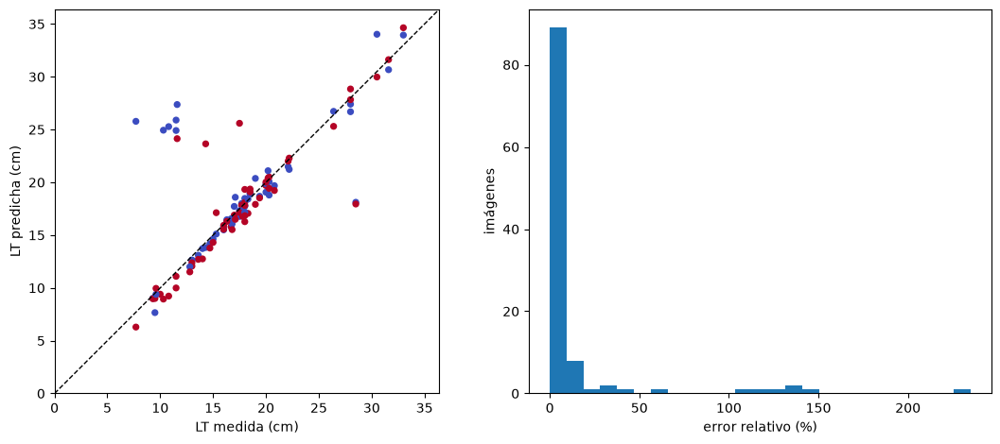

,ID_LADO,species,LT_cm,LT_pred_cm,dif_cm,dif_rel_pct,cola_doblada
50,13890_a,Astyanax erythropterus,7.7,25.78,18.08,234.80,True
44,13885_a,Potamorhina squamoralevis,11.6,27.37,15.77,135.95,True
74,13904_a,Roeboides affinis,10.3,24.94,14.64,142.12,True
58,13895_a,Roeboides affinis,10.8,25.28,14.48,134.06,True
46,13886_a,Potamorhina squamoralevis,11.5,25.90,14.40,125.20,True
52,13891_a,Astyanax rutilus,11.5,24.91,13.41,116.61,True
45,13885_b,Potamorhina squamoralevis,11.6,24.14,12.54,108.07,True
35,13879_b,Potamorhina squamoralevis,28.5,17.95,-10.55,37.03,True
34,13879_a,Potamorhina squamoralevis,28.5,18.11,-10.39,36.45,False
15,13868_b,Auchenipterus nigripinnis,14.3,23.65,9.35,65.36,True


In [6]:
def resumen(df, nombre):
    v = df.dropna(subset=["dif_cm"])
    e, a, r = v["dif_cm"], v["dif_abs_cm"], v["dif_rel_pct"]
    return pd.Series({
        "n": len(v), "sesgo (media dif con signo, cm)": e.mean(), "error abs medio (cm)": a.mean(),
        "error abs mediano (cm)": a.median(), "desvío error abs (cm)": a.std(), "desvío dif con signo (cm)": e.std(),
        "RMSE (cm)": np.sqrt((e ** 2).mean()), "error abs máx (cm)": a.max(), "error abs p90 (cm)": a.quantile(0.9),
        "error rel medio (%)": r.mean(), "error rel mediano (%)": r.median(), "desvío error rel (%)": r.std(),
        "error rel máx (%)": r.max(), "r Pearson": v["LT_pred_cm"].corr(v["LT_cm"])}, name=nombre)

tabla = pd.concat([resumen(res, "todas"), resumen(res[res["lado"] == "a"], "lado a"), resumen(res[res["lado"] == "b"], "lado b")], axis=1)
display(tabla.round(3))

v = res.dropna(subset=["LT_pred_cm"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
lim = [0, max(v["LT_cm"].max(), v["LT_pred_cm"].max()) * 1.05]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].scatter(v["LT_cm"], v["LT_pred_cm"], c=(v["lado"] == "b"), cmap="coolwarm", s=18)
ax[0].set_xlim(lim); ax[0].set_ylim(lim); ax[0].set_aspect("equal"); ax[0].set_xlabel("LT medida (cm)"); ax[0].set_ylabel("LT predicha (cm)")
ax[1].hist(v["dif_rel_pct"], bins=25); ax[1].set_xlabel("error relativo (%)"); ax[1].set_ylabel("imágenes")
plt.tight_layout(); plt.show()
v.sort_values("dif_abs_cm", ascending=False)[["ID_LADO", "species", "LT_cm", "LT_pred_cm", "dif_cm", "dif_rel_pct", "cola_doblada"]].head(10).round(2)

## Diferencia entre lados (a vs b) por individuo

In [7]:
p = res.pivot(index="ID", columns="lado", values="LT_pred_cm").dropna()
lados = pd.DataFrame({"pred_a_cm": p["a"], "pred_b_cm": p["b"]})
lados["LT_cm"] = res.groupby("ID")["LT_cm"].first()
lados["dif_lados_cm"] = (lados["pred_a_cm"] - lados["pred_b_cm"]).abs()
lados["dif_lados_pct"] = 100 * lados["dif_lados_cm"] / lados[["pred_a_cm", "pred_b_cm"]].mean(axis=1)
d, dp = lados["dif_lados_cm"], lados["dif_lados_pct"]
display(pd.DataFrame({"|a - b| (cm)": [d.mean(), d.median(), d.std(), d.max(), d.quantile(0.9)],
                      "|a - b| (% de la media de lados)": [dp.mean(), dp.median(), dp.std(), dp.max(), dp.quantile(0.9)]},
                     index=["media", "mediana", "desvío", "máx", "p90"]).round(3))
print(f"Individuos con ambos lados medidos: {len(lados)}")
lados.sort_values("dif_lados_cm", ascending=False).head(10).round(2)

,|a - b| (cm),|a - b| (% de la media de lados)
media,2.556,14.290
mediana,0.599,3.343
desvío,4.803,27.864
máx,19.490,121.546
p90,9.519,49.170


Individuos con ambos lados medidos: 54


,pred_a_cm,pred_b_cm,LT_cm,dif_lados_cm,dif_lados_pct
ID,,,,,
13890,25.78,6.29,7.7,19.49,121.55
13895,25.28,9.22,10.8,16.05,93.06
13904,24.94,8.94,10.3,16.00,94.44
13886,25.90,9.99,11.5,15.90,88.62
13891,24.91,11.10,11.5,13.82,76.74
13868,13.83,23.65,14.3,9.82,52.39
13866,16.77,25.59,17.5,8.82,41.66
13861,34.03,29.98,30.5,4.05,12.66
13885,27.37,24.14,11.6,3.23,12.56


## Excel de salida

In [8]:
cols = ["ID_LADO", "LT_pred_cm", "LT_cm", "dif_abs_cm", "dif_rel_pct"]
x_lado = res[cols].rename(columns={"LT_pred_cm": "LT_predicha_cm"}).sort_values("ID_LADO").round(3)

g = res.groupby("ID").agg(LT_predicha_cm=("LT_pred_cm", "mean"), LT_cm=("LT_cm", "first"))      # promedia ambos lados (ignora NaN)
g["dif_abs_cm"] = (g["LT_predicha_cm"] - g["LT_cm"]).abs()
g["dif_rel_pct"] = 100 * g["dif_abs_cm"] / g["LT_cm"]
x_id = g.reset_index().round(3)

SALIDA_XLSX_LADO.parent.mkdir(parents=True, exist_ok=True)
x_lado.to_excel(SALIDA_XLSX_LADO, index=False)
x_id.to_excel(SALIDA_XLSX_ID, index=False)
print(f"Guardados: {SALIDA_XLSX_LADO} ({len(x_lado)} filas), {SALIDA_XLSX_ID} ({len(x_id)} filas)")
x_id.head()

Guardados: outputs\muestreo_por_lado.xlsx (110 filas), outputs\muestreo_por_individuo.xlsx (55 filas)


,ID,LT_predicha_cm,LT_cm,dif_abs_cm,dif_rel_pct
0,13861,32.002,30.5,1.502,4.925
1,13862,26.015,26.4,0.385,1.457
2,13863,20.287,20.3,0.013,0.066
3,13864,17.916,17.7,0.216,1.221
4,13865,16.113,15.3,0.813,5.316


## Mosaico de resultados anotados

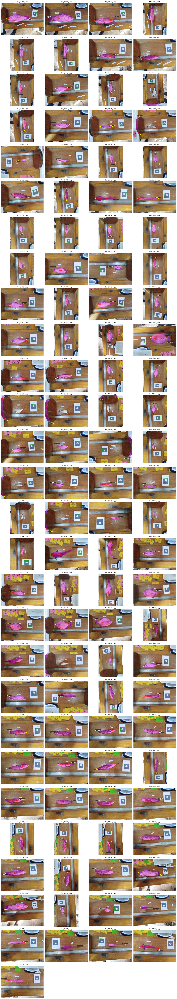

In [9]:
import math
import matplotlib.pyplot as plt

nombres = list(anotadas.keys())
total = len(nombres)

cols = 4
rows = math.ceil(total / cols)  # Redondea hacia arriba para que quepan todas

# Ajustamos el alto de la figura proporcionalmente a la cantidad de filas
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.2), squeeze=False)

# 1. Apagamos los ejes de TODAS las celdas (incluidas las que queden vacías al final)
for a in axes.ravel():
    a.axis("off")

# 2. Dibujamos cada imagen en su celda correspondiente
for a, n in zip(axes.ravel(), nombres):
    a.imshow(anotadas[n])
    a.set_title(n, fontsize=8)

plt.tight_layout()
plt.show()